# Proyecto #2: Pipeline de Machine Learning
## Notebook 05: Inferencia sobre test.csv
### Predict Future Sales (Kaggle)

**Objetivo:** usar el pipeline completo del notebook 04 (`models/full_pipeline.pkl`: preprocesamiento + modelo ganador) para predecir las ventas de **noviembre de 2015** (`date_block_num` = 34) de los 214,200 pares tienda-producto de `test.csv`, un mes que el modelo no ha visto.

**Salida:** `reports/submission.csv` con las columnas `ID` e `item_cnt_month` (formato de envío de Kaggle). Se guarda en `reports/` y no en `data/` porque la carpeta `data/` está excluida del repositorio en `.gitignore`, y el archivo de predicciones es uno de los entregables.

**Flujo:** `test.csv` solo trae `ID`, `shop_id` e `item_id`, así que primero se construyen sus variables con la **misma función** `build_feature_matrix` de los notebooks 02 a 04 (los lags del mes 34 salen de los meses 33, 32, 31, 28 y 22) y después se aplica el pipeline completo.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from predict_future_sales import features as F
from predict_future_sales.dataset import DATA_RAW, load_raw

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")
COLOR, COLOR_2 = "#2f6fae", "#d9822b"
MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")

## 1. Carga del pipeline completo

In [2]:
pipeline = joblib.load(MODELS_DIR / "full_pipeline.pkl")
print("Pasos del pipeline:")
for i, (nombre, paso) in enumerate(pipeline.steps, start=1):
    print(f"  {i:>2}. {nombre:<20} {type(paso).__name__}")

Pasos del pipeline:
   1. unificar_tiendas     Mapper
   2. imputar_lags         ArbitraryNumberImputer
   3. imputar_precio       MeanMedianImputer
   4. imputar_categoricas  CategoricalImputer
   5. codificar_ordinal    OrdinalEncoder
   6. codificar_onehot     OneHotEncoder
   7. eliminar_item_id     DropFeatures
   8. outliers_precio      Winsorizer
   9. log_precio           LogTransformer
  10. log_conteos          LogCpTransformer
  11. escalar              SklearnTransformerWrapper
  12. float32              DowncastFloat32
  13. modelo               RandomForestRegressor


## 2. Variables del mes 34 con la misma función de lags

Se construye la tabla completa con `build_feature_matrix` y se toman solo las filas del mes 34, que son exactamente los pares de `test.csv`. El objetivo de esas filas es desconocido (NaN) y no se usa. Luego se recupera el `ID` de cada par uniendo por `shop_id` e `item_id`.

In [3]:
raw = load_raw()
matriz = F.build_feature_matrix(raw)
X_test, _ = F.split_xy(matriz, [F.TEST_MONTH])
del matriz

test = raw["test"]
X_test = X_test.merge(test[["ID", "shop_id", "item_id"]], on=["shop_id", "item_id"], how="left", validate="one_to_one")
print(f"Filas del mes 34: {len(X_test):,} | filas de test.csv: {len(test):,}")
print("IDs recuperados:", X_test["ID"].notna().sum(), "| IDs únicos:", X_test["ID"].nunique(),
      "| ¿mismos IDs que test.csv?:", set(X_test["ID"]) == set(test["ID"]))

ids = X_test.pop("ID").to_numpy()
print("\nColumnas que recibe el pipeline:", X_test.columns.tolist())
X_test.head()

Filas del mes 34: 214,200 | filas de test.csv: 214,200
IDs recuperados: 214200 | IDs únicos: 214200 | ¿mismos IDs que test.csv?: True

Columnas que recibe el pipeline: ['date_block_num', 'shop_id', 'item_id', 'month', 'item_category_id', 'shop_city', 'item_cat_type', 'item_cat_subtype', 'item_cnt_month_lag_1', 'item_cnt_month_lag_2', 'item_cnt_month_lag_3', 'item_cnt_month_lag_6', 'item_cnt_month_lag_12', 'item_avg_cnt_lag_1', 'shop_avg_cnt_lag_1', 'shop_cat_avg_cnt_lag_1', 'item_price_last', 'item_age', 'item_is_new', 'shop_item_is_new']


,date_block_num,shop_id,item_id,month,item_category_id,shop_city,item_cat_type,item_cat_subtype,item_cnt_month_lag_1,item_cnt_month_lag_2,item_cnt_month_lag_3,item_cnt_month_lag_6,item_cnt_month_lag_12,item_avg_cnt_lag_1,shop_avg_cnt_lag_1,shop_cat_avg_cnt_lag_1,item_price_last,item_age,item_is_new,shop_item_is_new
0,34,5,5037,11,19,Вологда,Игры,PS3,0.0000,1.0000,3.0000,1.0000,1.0000,0.5682,0.1901,0.5137,"1,499.0000",14,0,0
1,34,5,5320,11,55,Вологда,Музыка,CD локального производства,NaN,NaN,NaN,NaN,NaN,NaN,0.1901,0.1582,NaN,0,1,1
2,34,5,5233,11,19,Вологда,Игры,PS3,1.0000,3.0000,1.0000,3.0000,NaN,0.9545,0.1901,0.5137,"1,199.0000",7,0,0
3,34,5,5232,11,23,Вологда,Игры,XBOX 360,0.0000,0.0000,1.0000,NaN,NaN,0.6364,0.1901,0.3741,"1,190.4333",3,0,0
4,34,5,5268,11,20,Вологда,Игры,PS4,NaN,NaN,NaN,NaN,NaN,NaN,0.1901,0.7965,NaN,0,1,1


In [4]:
# Qué historia tienen los pares de test (misma clasificación que la sección 10.b del EDA)
grupo = np.select(
    [X_test["item_is_new"] == 1, X_test["shop_item_is_new"] == 1],
    ["producto totalmente nuevo", "producto conocido, nuevo en la tienda"],
    default="par con historial",
)
print(pd.Series(grupo).value_counts().to_frame("pares").assign(**{"%": lambda d: d["pares"] / d["pares"].sum() * 100}))
print("\nNaN por variable antes del pipeline (los imputa el propio pipeline):")
print(X_test.isna().sum()[lambda s: s > 0].to_string())

                                        pares       %
par con historial                      111471 52.0406
producto conocido, nuevo en la tienda   87483 40.8417
producto totalmente nuevo               15246  7.1176

NaN por variable antes del pipeline (los imputa el propio pipeline):
shop_city                  10200
item_cat_subtype             546
item_cnt_month_lag_1       46578
item_cnt_month_lag_2       65247
item_cnt_month_lag_3       72504
item_cnt_month_lag_6       89519
item_cnt_month_lag_12     112807
item_avg_cnt_lag_1         46578
shop_cat_avg_cnt_lag_1        42
item_price_last            15246


**Interpretación:**

- El pipeline cargado tiene los 13 pasos esperados: los 12 de preprocesamiento del notebook 03 y el `RandomForestRegressor` ganador del notebook 04.
- `build_feature_matrix` genera exactamente **214,200 filas para el mes 34**, una por par de `test.csv`, y cada una recupera su `ID` sin duplicados ni faltantes.
- La composición de los pares es la misma que encontró el EDA (sección 10.b): **52.04%** con historial propio, **40.84%** de productos conocidos que nunca se vendieron en esa tienda y **7.12%** (15,246 pares) de productos totalmente nuevos.
- Las variables todavía tienen NaN (los lags de los pares sin historia, el precio de los productos nuevos, la ciudad de las tiendas 12 y 55 y el subtipo de algunas categorías). Es lo esperado: los imputa el propio pipeline, con los valores aprendidos en el entrenamiento.

## 3. Predicción

In [5]:
prediccion = np.clip(pipeline.predict(X_test), *F.TARGET_CLIP)

print("Distribución de las predicciones de noviembre de 2015:")
display(pd.Series(prediccion).describe(percentiles=[0.5, 0.75, 0.9, 0.99]).to_frame("item_cnt_month"))
print(f"Pares con predicción >= 1 unidad: {(prediccion >= 1).sum():,} ({(prediccion >= 1).mean() * 100:.1f}%)")
print(f"Pares con venta real >= 1 en octubre de 2015 (lag 1): {(X_test['item_cnt_month_lag_1'].fillna(0) >= 1).sum():,}")

total_oct = X_test["item_cnt_month_lag_1"].fillna(0).sum()
print(f"\nVenta total predicha para noviembre de 2015 (pares de test): {prediccion.sum():,.0f} unidades")
print(f"Venta real de esos pares en octubre de 2015 (recortada a 20): {total_oct:,.0f} unidades "
      f"-> variación {(prediccion.sum() / total_oct - 1) * 100:+.1f}%")

Distribución de las predicciones de noviembre de 2015:


,item_cnt_month
count,"214,200.0000"
mean,0.2973
std,0.7850
min,0.0001
50%,0.0841
75%,0.2638
90%,0.6529
99%,3.6601
max,19.0047


Pares con predicción >= 1 unidad: 12,721 (5.9%)
Pares con venta real >= 1 en octubre de 2015 (lag 1): 28,626

Venta total predicha para noviembre de 2015 (pares de test): 63,685 unidades
Venta real de esos pares en octubre de 2015 (recortada a 20): 54,760 unidades -> variación +16.3%


,pares,pred_media,octubre_media,pred_total
grupo,,,,
par con historial,111471,0.4078,0.4912,"45,461.7716"
"producto conocido, nuevo en la tienda",87483,0.0696,0.0000,"6,087.4077"
producto totalmente nuevo,15246,0.7960,0.0000,"12,135.7018"


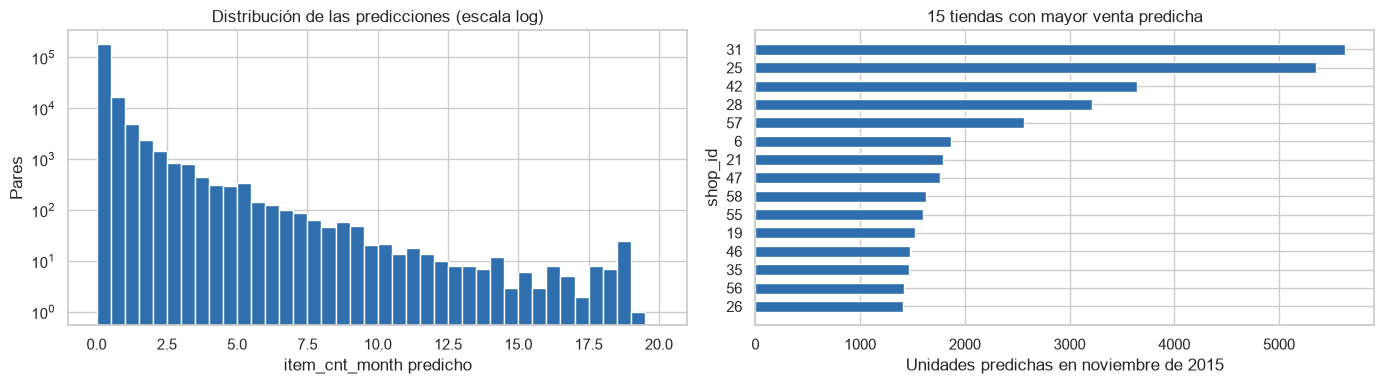

In [6]:
resumen = pd.DataFrame({"grupo": grupo, "predicción": prediccion, "octubre (lag 1)": X_test["item_cnt_month_lag_1"].fillna(0).to_numpy()})
por_grupo = resumen.groupby("grupo").agg(
    pares=("predicción", "size"),
    pred_media=("predicción", "mean"),
    octubre_media=("octubre (lag 1)", "mean"),
    pred_total=("predicción", "sum"),
)
display(por_grupo)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(prediccion, bins=np.arange(0, 20.5, 0.5), color=COLOR)
axes[0].set_yscale("log")
axes[0].set_title("Distribución de las predicciones (escala log)")
axes[0].set_xlabel("item_cnt_month predicho")
axes[0].set_ylabel("Pares")

por_tienda = pd.Series(prediccion).groupby(X_test["shop_id"].to_numpy()).sum().sort_values()
axes[1].barh([str(s) for s in por_tienda.index[-15:]], por_tienda.iloc[-15:], color=COLOR, height=0.6)
axes[1].set_title("15 tiendas con mayor venta predicha")
axes[1].set_xlabel("Unidades predichas en noviembre de 2015")
axes[1].set_ylabel("shop_id")
plt.tight_layout()
plt.show()

**Interpretación de las predicciones:**

- Las predicciones están entre 0 y 19 unidades, con mediana de 0.08 y media de 0.30, la misma escala que el objetivo de entrenamiento (media de 0.29, notebook 02). Solo el 5.9% de los pares (12,721) recibe una predicción de al menos 1 unidad, frente a 28,626 pares que vendieron al menos 1 unidad en octubre: el modelo reparte predicciones pequeñas entre muchos pares en lugar de asignar ventas enteras a pocos, lo que minimiza el RMSE cuando hay incertidumbre.
- **Pares con historial:** se predice una media de 0.41 unidades, por debajo de su venta de octubre (0.49). En conjunto, la predicción de estos pares es unas 9,300 unidades menor que lo que vendieron en octubre, en línea con la tendencia decreciente del EDA, aunque el EDA también mostró que noviembre suele superar a octubre (+2% a +10%). El modelo da más peso a la tendencia que a la estacionalidad, porque el lag 12 aporta poco (notebooks 02 y 04).
- **Productos conocidos, nuevos en la tienda:** media de 0.07, coherente con lo observado en el entrenamiento (0.05): un producto que nunca se vendió en una tienda rara vez empieza a venderse ahí.
- **Productos totalmente nuevos: media de 0.80 unidades por par, que suman 12,136 unidades (19% del total predicho).** Es el sesgo de construcción que se advirtió en el notebook 02: en el entrenamiento, un producto nuevo solo aparece en la cuadrícula del mes en que se vendió en alguna tienda (venta media de 0.67), mientras que en test los 363 productos nuevos aparecen en las 42 tiendas aunque muchos no se vayan a vender en todas. Es probable que estas predicciones estén **sobreestimadas**, y es el principal punto de mejora del modelo (por ejemplo, entrenando los productos nuevos con una cuadrícula que incluya todas las tiendas activas).
- En total se predicen 63,685 unidades, 16.3% más que lo que vendieron esos pares en octubre (54,760); esa subida viene de los productos nuevos, porque los pares con historia bajan.
- Las tiendas con mayor venta predicha son las grandes del EDA: la 31 (Москва ТЦ "Семеновский", unas 5,600 unidades), la 25 (Москва ТРК "Атриум"), la 42 (СПб ТК "Невский Центр") y la 28 (Москва ТЦ "МЕГА Теплый Стан" II). Esto confirma que el código de tienda (variable exógena) y los lags de tienda llevan el nivel de cada sucursal a la predicción.

## 4. Archivo de envío

In [7]:
submission = pd.DataFrame({"ID": ids.astype("int32"), "item_cnt_month": prediccion.astype("float32")}).sort_values("ID")
ruta = REPORTS_DIR / "submission.csv"
submission.to_csv(ruta, index=False)
print(f"Archivo guardado en {ruta} ({ruta.stat().st_size / 1e6:,.1f} MB)")

# Validación contra el formato de sample_submission.csv de Kaggle
ejemplo = pd.read_csv(DATA_RAW / "sample_submission.csv")
leido = pd.read_csv(ruta)
print("Mismas columnas que sample_submission:", leido.columns.tolist() == ejemplo.columns.tolist())
print("Mismo número de filas:", len(leido) == len(ejemplo), f"({len(leido):,})")
print("Mismos IDs:", leido["ID"].equals(ejemplo["ID"]))
print("Sin NaN:", leido.notna().all().all(), "| rango:", leido["item_cnt_month"].min(), "a", leido["item_cnt_month"].max())
leido.head()

Archivo guardado en ..\reports\submission.csv (4.0 MB)
Mismas columnas que sample_submission: True
Mismo número de filas: True (214,200)
Mismos IDs: True
Sin NaN: True | rango: 5.8775673e-05 a 19.004715


,ID,item_cnt_month
0,0,0.5553
1,1,0.4292
2,2,1.0496
3,3,0.4908
4,4,3.2848


**Conclusión:**

- Se generó **`reports/submission.csv`** con **214,200 filas** y las columnas **`ID` e `item_cnt_month`** en el formato de Kaggle: mismas columnas, mismo número de filas y mismos IDs que `sample_submission.csv`, sin NaN y con valores entre 0 y 20 (las predicciones se recortaron a [0, 20], igual que el objetivo).
- El flujo de inferencia usa solo dos piezas: la función `build_feature_matrix` (los lags del mes 34 se calculan con los meses 33, 32, 31, 28 y 22, sin información de noviembre) y el pipeline completo `models/full_pipeline.pkl`, que aplica el preprocesamiento y el Random Forest en un solo `predict`.
- El archivo se puede subir a la competencia de Kaggle para obtener el RMSE real de noviembre de 2015. El RMSE de validación del notebook 04 (0.8073) es la mejor estimación disponible antes de enviarlo; el sesgo de los productos nuevos descrito arriba puede hacer que el resultado real sea algo peor.